Energy prediction model

In [1]:
import pandas as pd
import numpy as np
dcgm=pd.read_csv(r"C:\Users\Harshvardhan\OneDrive\文档\developer\MLT\dcgm.csv\dcgm.csv")
scheduler = pd.read_csv(r"C:\Users\Harshvardhan\OneDrive\文档\developer\MLT\scheduler_data.csv\scheduler_data.csv")

print("DCGM:")
print(dcgm.shape)
print(dcgm.columns.tolist())

print("\nScheduler:")
print(scheduler.shape)
print(scheduler.columns.tolist())

DCGM:
(96893, 23)
['Node', 'avgmemoryutilization_pct', 'avgsmutilization_pct', 'energyconsumed_joules', 'gpu_id', 'maxgpumemoryused_bytes', 'memoryutilization_pct_avg', 'memoryutilization_pct_max', 'memoryutilization_pct_min', 'pcierxbandwidth_megabytes_avg', 'pcierxbandwidth_megabytes_max', 'pcierxbandwidth_megabytes_min', 'pcietxbandwidth_megabytes_avg', 'pcietxbandwidth_megabytes_max', 'pcietxbandwidth_megabytes_min', 'powerusage_watts_avg', 'powerusage_watts_max', 'powerusage_watts_min', 'smutilization_pct_avg', 'smutilization_pct_max', 'smutilization_pct_min', 'totalexecutiontime_sec', 'id_job']

Scheduler:
(287173, 31)
['id_array_job', 'id_array_task', 'id_user', 'kill_requid', 'nodes_alloc', 'nodelist', 'cpus_req', 'derived_ec', 'exit_code', 'gres_req', 'gres_alloc', 'gres_used', 'array_max_tasks', 'array_task_pending', 'constraints', 'flags', 'mem_req', 'partition', 'priority', 'state', 'timelimit', 'time_submit', 'time_eligible', 'time_start', 'time_end', 'time_suspended', 'tr

In [2]:
print(dcgm.dtypes)

Node                                 str
avgmemoryutilization_pct         float64
avgsmutilization_pct             float64
energyconsumed_joules            float64
gpu_id                             int64
maxgpumemoryused_bytes           float64
memoryutilization_pct_avg        float64
memoryutilization_pct_max        float64
memoryutilization_pct_min        float64
pcierxbandwidth_megabytes_avg    float64
pcierxbandwidth_megabytes_max    float64
pcierxbandwidth_megabytes_min    float64
pcietxbandwidth_megabytes_avg    float64
pcietxbandwidth_megabytes_max    float64
pcietxbandwidth_megabytes_min    float64
powerusage_watts_avg             float64
powerusage_watts_max             float64
powerusage_watts_min             float64
smutilization_pct_avg            float64
smutilization_pct_max            float64
smutilization_pct_min            float64
totalexecutiontime_sec           float64
id_job                             int64
dtype: object


In [3]:
print(scheduler.dtypes)

id_array_job            int64
id_array_task           int64
id_user                 int64
kill_requid             int64
nodes_alloc             int64
nodelist                  str
cpus_req                int64
derived_ec              int64
exit_code               int64
gres_req                  str
gres_alloc                str
gres_used             float64
array_max_tasks         int64
array_task_pending      int64
constraints               str
flags                   int64
mem_req                uint64
partition                 str
priority                int64
state                   int64
timelimit               int64
time_submit             int64
time_eligible           int64
time_start              int64
time_end                int64
time_suspended          int64
track_steps             int64
tres_alloc                str
tres_req                  str
job_type                  str
id_job                  int64
dtype: object


In [4]:
dcgm.head()

,Node,avgmemoryutilization_pct,avgsmutilization_pct,energyconsumed_joules,gpu_id,maxgpumemoryused_bytes,memoryutilization_pct_avg,memoryutilization_pct_max,memoryutilization_pct_min,pcierxbandwidth_megabytes_avg,...,pcietxbandwidth_megabytes_max,pcietxbandwidth_megabytes_min,powerusage_watts_avg,powerusage_watts_max,powerusage_watts_min,smutilization_pct_avg,smutilization_pct_max,smutilization_pct_min,totalexecutiontime_sec,id_job
0,r9170217-n750018,0.0,1.0,157521.0,0,2.645557e+09,3.0,24.0,0.0,1646.0,...,1530.0,676.0,44.0546,156.962,25.468,11.0,64.0,0.0,4452.47,4393785332
1,r44132-n469339,0.0,0.0,0.0,1,0.000000e+00,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0000,0.000,0.000,0.0,0.0,0.0,0.54,18177101425
2,r5354770-n172107,0.0,3.0,94816.0,0,2.917171e+07,0.0,0.0,0.0,1846.0,...,1872.0,1346.0,26.3725,27.483,25.979,6.0,43.0,0.0,8398.30,39529488078
3,r1900814-n772143,0.0,0.0,69451.0,0,1.527587e+09,0.0,1.0,0.0,539.0,...,337.0,293.0,37.5481,52.039,26.676,1.0,25.0,0.0,1851.72,19994333952
4,r9515777-n469339,0.0,0.0,0.0,1,0.000000e+00,0.0,0.0,0.0,1991.0,...,1109.0,1109.0,25.0320,25.032,25.032,0.0,0.0,0.0,0.99,397881706


In [5]:
scheduler.head()

,id_array_job,id_array_task,id_user,kill_requid,nodes_alloc,nodelist,cpus_req,derived_ec,exit_code,gres_req,...,time_submit,time_eligible,time_start,time_end,time_suspended,track_steps,tres_alloc,tres_req,job_type,id_job
0,41161693674,4595979483,66088413977,51671871839,0,[],1,0,256,NaN,...,3014,3014,3014,3014,-1,0,NaN,"1=1,2=5000,4=1,5=1,1002=2",OTHER,13715936505
1,41161693674,4595979483,66088413977,51671871839,1,['r2684277-n303509'],1,0,0,gpu:volta:2,...,3022,3022,3022,3025,-1,0,"1=1,2=9600,4=1,5=1,1002=2","1=1,2=9600,4=1,5=1,1002=2",OTHER,25780056187
2,41161693674,4595979483,16176946191,51671871839,1,['r5198790-n347934'],4,32512,32512,gpu:volta:1,...,5682,5682,5683,5684,-1,0,"1=4,2=38400,4=1,5=4,1002=1","1=4,2=38400,4=1,5=4,1002=1",OTHER,53722449986
3,41161693674,4595979483,16176946191,16176946191,1,['r3541344-n655125'],4,0,0,gpu:volta:1,...,34467,34467,34468,34548,-1,0,"1=4,2=20000,4=1,5=4,1002=1","1=4,2=20000,4=1,5=4,1002=1",OTHER,19989272070
4,41161693674,4595979483,16176946191,16176946191,1,['r3541344-n655125'],4,0,0,gpu:volta:1,...,34596,34596,34596,35108,-1,0,"1=4,2=20000,4=1,5=4,1002=1","1=4,2=20000,4=1,5=4,1002=1",OTHER,49220239266


In [6]:
# Keeping scheduler fields needed for hourly grouping and workload features
scheduler_columns = [
    "id_job",
    "cpus_req",
    "gres_req",
    "mem_req",
    "tres_req",
    "job_type",
    "time_submit",
    "time_start",
    "time_end",
]

scheduler_reduced = scheduler[scheduler_columns].copy()

# Using one resource row per job
scheduler_jobs = (
    scheduler_reduced
    .drop_duplicates(subset="id_job", keep="first")
    [["id_job", "cpus_req", "gres_req", "mem_req", "tres_req", "job_type"]]
    .copy()
)

# Keeping job timing information from all scheduler rows
scheduler_times = (
    scheduler_reduced
    .groupby("id_job", as_index=False)
    .agg(
        time_submit=("time_submit", "min"),
        time_start=("time_start", "min"),
        time_end=("time_end", "max"),
    )
)

# Removing only exact duplicate DCGM records.
# Multiple rows for the same job can represent separate GPUs.
dcgm_clean = dcgm.drop_duplicates().copy()

# Aggregate DCGM measurements to one row per job
dcgm_jobs = (
    dcgm_clean
    .groupby("id_job", as_index=False)
    .agg(
        energyconsumed_joules=("energyconsumed_joules", "sum"),
        execution_time_sec=("totalexecutiontime_sec", "max"),
        gpu_count=("gpu_id", "nunique"),
    )
)

# Merging scheduler features, job times, and DCGM by job ID
jobs = (
    scheduler_jobs
    .merge(
        scheduler_times,
        on="id_job",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        dcgm_jobs,
        on="id_job",
        how="inner",
        validate="one_to_one",
    )
)

# Putting jobs in chronological submission order
jobs = jobs.sort_values("time_submit").reset_index(drop=True)

print("Jobs after merge:", len(jobs))
print("Duplicate job IDs:", jobs["id_job"].duplicated().sum())
display(jobs.head())

Jobs after merge: 74849
Duplicate job IDs: 0


,id_job,cpus_req,gres_req,mem_req,tres_req,job_type,time_submit,time_start,time_end,energyconsumed_joules,execution_time_sec,gpu_count
0,19420841135,1,gpu:volta:1,9223372036854784308,"1=1,2=8500,4=1,5=1,1002=1",LLSUB:INTERACTIVE,21193772,21193772,21193877,3005.0,105.72,1
1,32036696931,20,gpu:volta:2,9223372036854784308,"1=20,2=170000,4=1,5=20,1002=2",OTHER,21197641,21197642,21197707,3776.0,66.56,2
2,2911758054,20,gpu:volta:1,9223372036854784308,"1=20,2=170000,4=1,5=20,1002=1",OTHER,21197691,21197698,21197707,258.0,10.51,1
3,28837092798,20,gpu:volta:1,9223372036854784308,"1=20,2=170000,4=1,5=20,1002=1",OTHER,21197718,21197718,21198457,83021.0,738.94,1
4,20817022395,40,gpu:volta:2,9223372036854784308,"1=40,2=340000,4=1,5=40,1002=2",OTHER,21197732,21197738,21198139,87819.0,400.43,2


conversion of slurm memory to memory in bytes

In [7]:
# Extract the memory value (TRES ID 2) from strings like "1=4,2=38400,4=1"
mem_mib = pd.to_numeric(
    jobs["tres_req"]
    .astype("string")
    .str.extract(r"(?:^|,)2=(\d+)(?:,|$)")[0],
    errors="coerce",
)

# Convert MiB to bytes
jobs["mem_req_total_bytes"] = (mem_mib * 1024**2).round().astype("Int64")

print("Jobs missing TRES memory:", jobs["mem_req_total_bytes"].isna().sum())
display(jobs[["id_job", "tres_req", "mem_req_total_bytes"]].head())

Jobs missing TRES memory: 470


,id_job,tres_req,mem_req_total_bytes
0,19420841135,"1=1,2=8500,4=1,5=1,1002=1",8912896000
1,32036696931,"1=20,2=170000,4=1,5=20,1002=2",178257920000
2,2911758054,"1=20,2=170000,4=1,5=20,1002=1",178257920000
3,28837092798,"1=20,2=170000,4=1,5=20,1002=1",178257920000
4,20817022395,"1=40,2=340000,4=1,5=40,1002=2",356515840000


dropping where 2= mem requirement not  given

In [8]:
jobs = jobs.dropna(subset=["mem_req_total_bytes"]).copy()

In [9]:
gres = jobs["gres_req"].astype("string")

jobs["gpu_req_count"] = pd.to_numeric(
    gres.str.extract(r":(\d+)\s*$")[0],
    errors="coerce",
).fillna(0)

jobs["cpus_req"] = pd.to_numeric(jobs["cpus_req"], errors="coerce").fillna(0)
jobs["time_submit"] = pd.to_numeric(jobs["time_submit"], errors="coerce")

In [ ]:
# Excluding jobs without a usable submission time or energy target
jobs = jobs.dropna(subset=["time_submit", "energyconsumed_joules"]).copy()

# shifting the first submission time to zero
jobs = jobs.sort_values("time_submit").reset_index(drop=True)
jobs["time_submit_shifted"] = jobs["time_submit"] - jobs["time_submit"].min()

# Each job belongs to the hour in which it was submitted
jobs["submit_hour"] = (jobs["time_submit_shifted"] // 3600).astype(int)
jobs["job_type"] = jobs["job_type"].fillna("unknown").astype(str)

# Overall hourly totals
hourly = (
    jobs.groupby("submit_hour")
    .agg(
        n_jobs=("id_job", "nunique"),
        n_gpus=("gpu_req_count", "sum"),
        n_cpus=("cpus_req", "sum"),
        memory_bytes=("mem_req_total_bytes", "sum"),
        execution_time_sec_sum=("execution_time_sec", "sum"),
        hourly_energy_joules=("energyconsumed_joules", "sum"),
       
    )
)

# Keeping each job type's hourly job count as its own feature column
job_type_counts = pd.crosstab(
    jobs["submit_hour"],
    jobs["job_type"],
).add_prefix("jobs_type_")

# Include hours with no submissions between the first and last hour
all_hours = pd.RangeIndex(
    start=0,
    stop=int(jobs["submit_hour"].max()) + 1,
    name="submit_hour",
)
hourly = hourly.reindex(all_hours)
job_type_counts = job_type_counts.reindex(all_hours, fill_value=0)
hourly = hourly.join(job_type_counts)

# No submissions = zero jobs/resources/energy in that hour
zero_when_empty = [
    "n_jobs", "n_gpus", "n_cpus", "memory_bytes",
    "execution_time_sec_sum", "hourly_energy_joules"
]
hourly[zero_when_empty] = hourly[zero_when_empty].fillna(0)
hourly[job_type_counts.columns] = hourly[job_type_counts.columns].fillna(0)

hourly["hour_start_seconds"] = hourly.index * 3600
hourly = hourly.reset_index()

display(hourly.head())

,submit_hour,n_jobs,n_gpus,n_cpus,memory_bytes,execution_time_sec_sum,hourly_energy_joules,jobs_type_LLMAPREDUCE:MAP,jobs_type_LLSUB:BATCH,jobs_type_LLSUB:INTERACTIVE,jobs_type_OTHER,hour_start_seconds
0,0,1.0,1,1.0,8912896000,105.72,3005.0,0,0,1,0,0
1,1,6.0,12,184.0,1639972864000,9534.36,457742.0,0,0,0,6,3600
2,2,65.0,102,715.0,5822427955200,108907.46,5618588.0,0,0,1,64,7200
3,3,4.0,5,4.0,35651584000,4257.73,347238.0,0,0,2,2,10800
4,4,0.0,0,0.0,0,0.00,0.0,0,0,0,0,14400


In [11]:
hourly.info

<bound method DataFrame.info of       submit_hour  n_jobs  n_gpus  n_cpus   memory_bytes  \
0               0     1.0       1     1.0     8912896000   
1               1     6.0      12   184.0  1639972864000   
2               2    65.0     102   715.0  5822427955200   
3               3     4.0       5     4.0    35651584000   
4               4     0.0       0     0.0              0   
...           ...     ...     ...     ...            ...   
2998         2998    14.0      14   280.0  2495610880000   
2999         2999     8.0       9   141.0  1256718336000   
3000         3000    12.0      12   108.0   962592768000   
3001         3001     2.0       2    80.0   713031680000   
3002         3002     1.0       1     1.0     8912896000   

      execution_time_sec_sum  hourly_energy_joules  jobs_type_LLMAPREDUCE:MAP  \
0                     105.72                3005.0                          0   
1                    9534.36              457742.0                          0   
2   

With execution time as feature:taking for prediction simplicity will remove later and compare performance

In [12]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Keeping the hours in chronological order
hourly = hourly.sort_values("submit_hour").reset_index(drop=True)

target = "hourly_energy_joules"

# removing hour_start_seconds
X = hourly.drop(columns=[target, "hour_start_seconds"])
y = hourly[target]

#  70% train, 15% validation, 15% test
n = len(hourly)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

# A simple model to reduce overfitting on this dataset size
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train)

def report_scores(name, actual, predicted):
    print(
        f"{name}: "
        f"MAE={mean_absolute_error(actual, predicted):,.1f} J | "
        f"RMSE={np.sqrt(mean_squared_error(actual, predicted)):,.1f} J | "
        f"R²={r2_score(actual, predicted):.3f}"
    )

# Comparing on validation data
validation_prediction = model.predict(X_val)
median_baseline = np.full(len(y_val), y_train.median())

report_scores("Training-median baseline — validation", y_val, median_baseline)
report_scores("Random Forest — validation", y_val, validation_prediction)

Training-median baseline — validation: MAE=2,151,266.1 J | RMSE=6,023,903.0 J | R²=-0.045
Random Forest — validation: MAE=1,331,326.2 J | RMSE=3,764,020.2 J | R²=0.592


In [13]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

final_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)
final_model.fit(X_train_val, y_train_val)

test_prediction = final_model.predict(X_test)
report_scores("Final Random Forest — test", y_test, test_prediction)

Final Random Forest — test: MAE=2,309,056.0 J | RMSE=8,244,006.4 J | R²=0.337


In [14]:
report_scores(
    "Training-median baseline — test",
    y_test,
    np.full(len(y_test), y_train_val.median()),
)

report_scores(
    "Training-mean baseline — test",
    y_test,
    np.full(len(y_test), y_train_val.mean()),
)

Training-median baseline — test: MAE=2,933,235.5 J | RMSE=10,395,490.1 J | R²=-0.054
Training-mean baseline — test: MAE=3,692,157.0 J | RMSE=10,126,905.8 J | R²=-0.000


In [15]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor

def make_rf():
    return RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )

# Raw-energy model
raw_rf = make_rf()
raw_rf.fit(X_train, y_train)
raw_val_pred = np.maximum(0, raw_rf.predict(X_val))

# Log-energy model convert predictions back to joules
log_rf = make_rf()
log_rf.fit(X_train, np.log1p(y_train))
log_val_pred = np.maximum(0, np.expm1(log_rf.predict(X_val)))

report_scores("Raw-target RF — validation", y_val, raw_val_pred)
report_scores("Log-target RF — validation", y_val, log_val_pred)

Raw-target RF — validation: MAE=1,331,326.2 J | RMSE=3,764,020.2 J | R²=0.592
Log-target RF — validation: MAE=1,178,658.0 J | RMSE=3,861,136.5 J | R²=0.571


In [16]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

log_rf_final = make_rf()
log_rf_final.fit(X_train_val, np.log1p(y_train_val))

log_test_pred = np.maximum(
    0,
    np.expm1(log_rf_final.predict(X_test)),
)

report_scores("Log-target RF — test", y_test, log_test_pred)

Log-target RF — test: MAE=2,063,378.8 J | RMSE=8,585,418.1 J | R²=0.281


In [17]:
raw_test_pred = final_model.predict(X_test)

for name, prediction in [
    ("Raw-target RF", raw_test_pred),
    ("Log-target RF", log_test_pred),
]:
    actual_total = y_test.sum()
    predicted_total = prediction.sum()
    print(
        f"{name}: actual={actual_total:,.0f} J, "
        f"predicted={predicted_total:,.0f} J, "
        f"difference={predicted_total - actual_total:,.0f} J "
        f"({100 * (predicted_total - actual_total) / actual_total:.1f}%)"
    )

Raw-target RF: actual=1,445,059,094 J, predicted=1,393,316,684 J, difference=-51,742,410 J (-3.6%)
Log-target RF: actual=1,445,059,094 J, predicted=1,031,090,171 J, difference=-413,968,923 J (-28.6%)


Now using XGBoost

In [18]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=2000,      
    eval_metric="mae",
    early_stopping_rounds=60,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

xgb_val_pred = np.maximum(0, xgb_model.predict(X_val))

report_scores("XGBoost — validation", y_val, xgb_val_pred)
print("Best iteration:", xgb_model.best_iteration)

XGBoost — validation: MAE=1,313,380.2 J | RMSE=3,760,116.1 J | R²=0.593
Best iteration: 105


In [19]:
import pandas as pd
from xgboost import XGBRegressor

X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

xgb_final = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=xgb_model.best_iteration + 1,
    eval_metric="mae",
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

xgb_final.fit(X_train_val, y_train_val)

xgb_test_pred = np.maximum(0, xgb_final.predict(X_test))
report_scores("XGBoost — test", y_test, xgb_test_pred)

XGBoost — test: MAE=2,239,032.8 J | RMSE=8,198,879.9 J | R²=0.345


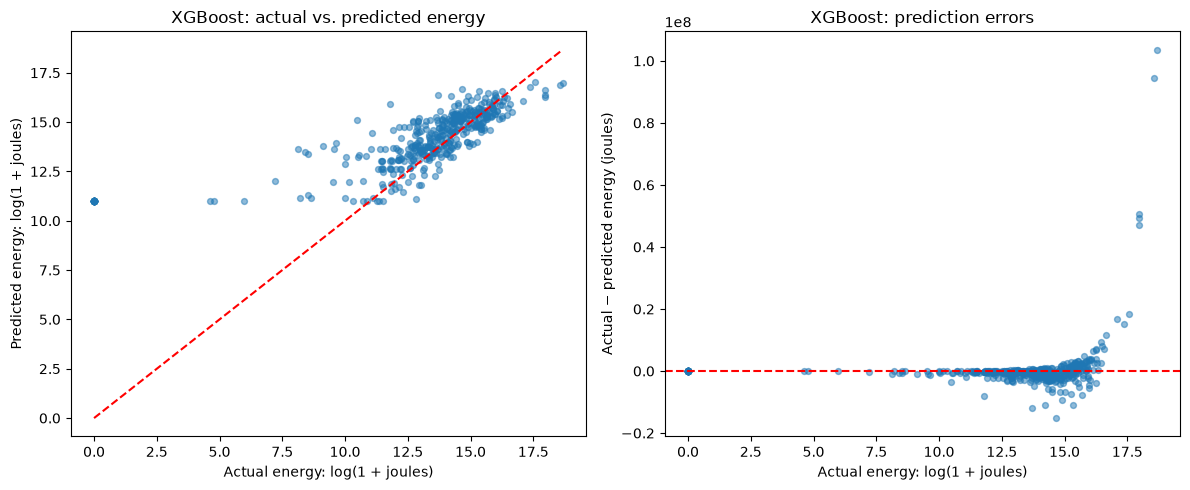

In [20]:
import matplotlib.pyplot as plt
import numpy as np

actual = np.asarray(y_test)
predicted = np.maximum(0, np.asarray(xgb_test_pred))
residuals = actual - predicted

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs. predicted energy, on log1p scales
actual_log = np.log1p(actual)
predicted_log = np.log1p(predicted)

axes[0].scatter(actual_log, predicted_log, alpha=0.5, s=18)
low = min(actual_log.min(), predicted_log.min())
high = max(actual_log.max(), predicted_log.max())
axes[0].plot([low, high], [low, high], "r--")
axes[0].set(
    title="XGBoost: actual vs. predicted energy",
    xlabel="Actual energy: log(1 + joules)",
    ylabel="Predicted energy: log(1 + joules)",
)

# Residuals in joules, against actual energy on a log1p scale
axes[1].scatter(actual_log, residuals, alpha=0.5, s=18)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set(
    title="XGBoost: prediction errors",
    xlabel="Actual energy: log(1 + joules)",
    ylabel="Actual − predicted energy (joules)",
)

plt.tight_layout()
plt.show()

Tuning XGBRegressor

In [21]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def get_scores(y_true, y_pred):
    return {
        "MAE_J": mean_absolute_error(y_true, y_pred),
        "RMSE_J": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

search_space = {
    "learning_rate": [0.03, 0.05, 0.08],
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [3, 10, 20],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "reg_lambda": [1, 10, 30],
}

candidates = list(ParameterSampler(
    search_space,
    n_iter=12,
    random_state=42,
))

results = []
trained_models = []

for params in candidates:
    candidate = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=2000,        
        eval_metric="mae",
        early_stopping_rounds=60,
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
        **params,
    )

    candidate.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False,
    )

    val_pred = np.maximum(0, candidate.predict(X_val))
    scores = get_scores(y_val, val_pred)

    results.append({
        **params,
        "best_iteration": candidate.best_iteration,
        **scores,
    })
    trained_models.append((scores["MAE_J"], params, candidate))

xgb_tuning_results = (
    pd.DataFrame(results)
    .sort_values("MAE_J")
    .reset_index(drop=True)
)
display(xgb_tuning_results)

best_xgb_mae, best_xgb_params, best_xgb = min(
    trained_models,
    key=lambda item: item[0],
)

print("Best parameters:", best_xgb_params)
print("Best iteration:", best_xgb.best_iteration)
print(
    "Best validation scores:",
    get_scores(y_val, np.maximum(0, best_xgb.predict(X_val))),
)

,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,colsample_bytree,best_iteration,MAE_J,RMSE_J,R2
0,1.00,10,10,3,0.08,0.85,253,1.249792e+06,3.790472e+06,0.586124
1,0.85,30,3,5,0.08,0.70,141,1.252088e+06,3.950285e+06,0.550489
2,0.85,30,10,5,0.03,0.70,243,1.264001e+06,3.863338e+06,0.570059
3,0.85,1,10,5,0.08,0.70,104,1.271996e+06,3.691589e+06,0.607436
4,1.00,1,10,3,0.05,1.00,159,1.286131e+06,3.751141e+06,0.594668
5,0.70,10,3,3,0.08,1.00,81,1.287039e+06,3.837092e+06,0.575881
6,0.85,10,20,6,0.05,0.85,235,1.292536e+06,3.701346e+06,0.605358
7,1.00,30,20,4,0.05,0.85,110,1.298346e+06,3.868195e+06,0.568977
8,0.70,1,20,6,0.05,1.00,149,1.300281e+06,3.788145e+06,0.586632
9,1.00,10,20,6,0.08,0.85,61,1.308061e+06,3.793465e+06,0.585470


Best parameters: {'subsample': 1.0, 'reg_lambda': 10, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.08, 'colsample_bytree': 0.85}
Best iteration: 253
Best validation scores: {'MAE_J': 1249792.3078493923, 'RMSE_J': np.float64(3790471.6567392885), 'R2': 0.5861239062274431}


In [22]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

tuned_xgb_final = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=best_xgb.best_iteration + 1,
    eval_metric="mae",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    **best_xgb_params,
)

tuned_xgb_final.fit(X_train_val, y_train_val)

tuned_xgb_test_pred = np.maximum(
    0,
    tuned_xgb_final.predict(X_test),
)

report_scores("Tuned XGBoost — test", y_test, tuned_xgb_test_pred)

Tuned XGBoost — test: MAE=2,150,823.7 J | RMSE=8,327,510.6 J | R²=0.324


In [23]:
actual_total = y_test.sum()
tuned_total = tuned_xgb_test_pred.sum()

print(f"Actual:    {actual_total:,.0f} J")
print(f"Tuned XGB: {tuned_total:,.0f} J")
print(
    f"Difference: {tuned_total - actual_total:,.0f} J "
    f"({100 * (tuned_total - actual_total) / actual_total:.1f}%)"
)

Actual:    1,445,059,094 J
Tuned XGB: 1,124,412,672 J
Difference: -320,646,422 J (-22.2%)


random forest model tuning

In [24]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def get_scores(y_true, y_pred):
    return {
        "MAE_J": mean_absolute_error(y_true, y_pred),
        "RMSE_J": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

search_space = {
    "max_depth": [None, 8, 12, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": [0.7, 1.0],
    "max_samples": [0.7, 1.0],
}

candidates = list(ParameterSampler(
    search_space,
    n_iter=12,
    random_state=42,
))

results = []
trained_models = []

for params in candidates:
    candidate = RandomForestRegressor(
        n_estimators=300,
        bootstrap=True,
        random_state=42,
        n_jobs=-1,
        **params,
    )

    # Raw target trained directly on joules
    candidate.fit(X_train, y_train)
    val_pred = np.maximum(0, candidate.predict(X_val))
    scores = get_scores(y_val, val_pred)

    results.append({**params, **scores})
    trained_models.append((scores["MAE_J"], params))

rf_tuning_results = (
    pd.DataFrame(results)
    .sort_values("MAE_J")
    .reset_index(drop=True)
)
display(rf_tuning_results)

best_rf_mae, best_rf_params = min(
    trained_models,
    key=lambda item: item[0],
)

print("Best parameters:", best_rf_params)
print("Best validation scores:", rf_tuning_results.iloc[0][["MAE_J", "RMSE_J", "R2"]])

,min_samples_leaf,max_samples,max_features,max_depth,MAE_J,RMSE_J,R2
0,5,0.7,1.0,20.0,1.316908e+06,3.788107e+06,0.586640
1,1,0.7,0.7,8.0,1.321914e+06,3.744332e+06,0.596138
2,2,0.7,1.0,8.0,1.332501e+06,3.720404e+06,0.601284
3,2,1.0,0.7,NaN,1.340302e+06,3.745185e+06,0.595954
4,2,0.7,1.0,NaN,1.347256e+06,3.740085e+06,0.597054
5,1,0.7,0.7,NaN,1.351022e+06,3.730544e+06,0.599107
6,1,1.0,0.7,12.0,1.372541e+06,3.806069e+06,0.582711
7,2,1.0,1.0,20.0,1.373276e+06,3.781954e+06,0.587982
8,1,1.0,0.7,20.0,1.376808e+06,3.773376e+06,0.589849
9,1,0.7,1.0,20.0,1.386502e+06,3.792395e+06,0.585704


Best parameters: {'min_samples_leaf': 5, 'max_samples': 0.7, 'max_features': 1.0, 'max_depth': 20}
Best validation scores: MAE_J     1.316908e+06
RMSE_J    3.788107e+06
R2        5.866402e-01
Name: 0, dtype: float64


In [25]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

rf_final = RandomForestRegressor(
    n_estimators=300,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
    **best_rf_params,
)

rf_final.fit(X_train_val, y_train_val)
rf_test_pred = np.maximum(0, rf_final.predict(X_test))

print("Tuned raw-target RF — test:", get_scores(y_test, rf_test_pred))

Tuned raw-target RF — test: {'MAE_J': 2312149.7814231156, 'RMSE_J': np.float64(8241285.632561423), 'R2': 0.3377142002367294}


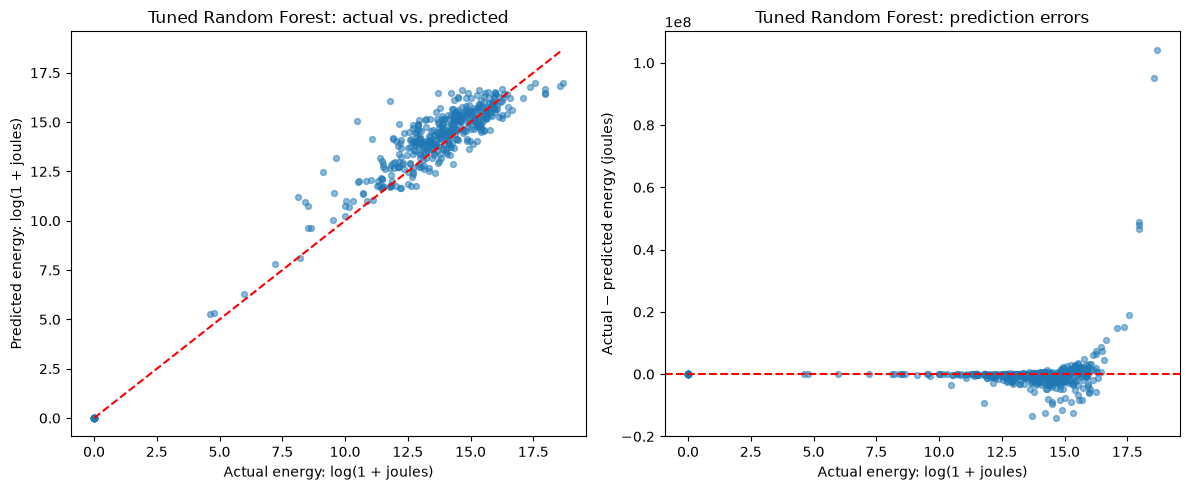

In [26]:
import matplotlib.pyplot as plt

actual = np.asarray(y_test)
predicted = np.asarray(rf_test_pred)
residuals = actual - predicted

actual_log = np.log1p(actual)
predicted_log = np.log1p(predicted)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(actual_log, predicted_log, alpha=0.5, s=18)
low = min(actual_log.min(), predicted_log.min())
high = max(actual_log.max(), predicted_log.max())
axes[0].plot([low, high], [low, high], "r--")
axes[0].set(
    title="Tuned Random Forest: actual vs. predicted",
    xlabel="Actual energy: log(1 + joules)",
    ylabel="Predicted energy: log(1 + joules)",
)

axes[1].scatter(actual_log, residuals, alpha=0.5, s=18)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set(
    title="Tuned Random Forest: prediction errors",
    xlabel="Actual energy: log(1 + joules)",
    ylabel="Actual − predicted energy (joules)",
)

plt.tight_layout()
plt.show()

In [27]:
actual_total = y_test.sum()
tuned_total = rf_test_pred.sum()

print(f"Actual: {actual_total:,.0f} J")
print(f"Tuned RF: {tuned_total:,.0f} J")
print(
    f"Difference: {tuned_total - actual_total:,.0f} J "
    f"({100 * (tuned_total - actual_total) / actual_total:.1f}%)"
)

Actual: 1,445,059,094 J
Tuned RF: 1,390,949,425 J
Difference: -54,109,669 J (-3.7%)


% difference is much lower in raw target RF than xgboost model

checking how is test set and training set distributed

In [28]:
features = ["n_jobs", "n_cpus", "n_gpus"]

# Comparing the feature distributions by chronological split
for split_name, frame in [("Train", X_train), ("Test", X_test)]:
    print(f"\n{split_name} workload features")
    display(
        frame[features]
        .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
        .T
    )

# Checking how many test hours fall outside each feature's training range
for feature in features:
    train_min = X_train[feature].min()
    train_max = X_train[feature].max()
    outside = (
        (X_test[feature] < train_min) |
        (X_test[feature] > train_max)
    ).mean()

    print(
        f"{feature}: train range={train_min:g}–{train_max:g}, "
        f"test hours outside that range={outside:.1%}"
    )


Train workload features


,count,mean,std,min,50%,90%,95%,99%,max
n_jobs,2102.0,26.868696,312.624704,0.0,7.0,45.9,74.0,229.95,14134.0
n_cpus,2102.0,359.843482,1007.810268,0.0,118.5,828.3,1344.0,3268.31,23835.0
n_gpus,2102.0,35.747383,315.633974,0.0,11.0,67.0,107.0,275.96,14134.0



Test workload features


,count,mean,std,min,50%,90%,95%,99%,max
n_jobs,451.0,23.133038,66.032181,0.0,8.0,49.0,84.5,213.0,1127.0
n_cpus,451.0,237.035477,347.72512,0.0,140.0,564.0,775.5,1421.5,3281.0
n_gpus,451.0,26.543237,68.310141,0.0,10.0,58.0,93.0,228.5,1127.0


n_jobs: train range=0–14134, test hours outside that range=0.0%
n_cpus: train range=0–23835, test hours outside that range=0.0%
n_gpus: train range=0–14134, test hours outside that range=0.0%


rolling time based test without runtime

In [29]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


data = hourly.sort_values("submit_hour").reset_index(drop=True)
target = "hourly_energy_joules"


job_type_cols = [
    col for col in data.columns
    if col.startswith("jobs_type_")
]

# Excluding measured execution_time_sec_sum as it isn't known at arrival.
feature_cols = [
    "submit_hour",
    "n_jobs",
    "n_gpus",
    "n_cpus",
    "memory_bytes",
] + job_type_cols

X_live = data[feature_cols].fillna(0)
y = data[target]

def scores(y_true, y_pred):
    return {
        "MAE_J": mean_absolute_error(y_true, y_pred),
        "RMSE_J": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

# Five successive one-week prediction windows
splitter = TimeSeriesSplit(n_splits=5, test_size=168)
fold_results = []
out_of_sample = []

for fold, (train_idx, forecast_idx) in enumerate(splitter.split(X_live), start=1):
    X_past = X_live.iloc[train_idx]
    y_past = y.iloc[train_idx]
    X_future = X_live.iloc[forecast_idx]
    y_future = y.iloc[forecast_idx]

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=5,
        max_features=1.0,
        max_samples=0.7,
        bootstrap=True,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_past, y_past)

    prediction = np.maximum(0, model.predict(X_future))

    # Baseline predict the median energy from earlier hours
    median_baseline = np.full(len(y_future), y_past.median())

    fold_results.append({
        "fold": fold,
        "first_forecast_hour": int(data.loc[forecast_idx[0], "submit_hour"]),
        "last_forecast_hour": int(data.loc[forecast_idx[-1], "submit_hour"]),
        **{f"RF_{k}": v for k, v in scores(y_future, prediction).items()},
        **{f"Median_{k}": v for k, v in scores(y_future, median_baseline).items()},
    })

    out_of_sample.append(pd.DataFrame({
        "submit_hour": data.loc[forecast_idx, "submit_hour"].to_numpy(),
        "actual_j": y_future.to_numpy(),
        "predicted_j": prediction,
        "median_baseline_j": median_baseline,
    }))

fold_results = pd.DataFrame(fold_results)
display(fold_results)

# Pooled performance across all five future-week windows
out_of_sample = pd.concat(out_of_sample, ignore_index=True)

print("Pooled walk-forward RF:", scores(
    out_of_sample["actual_j"], out_of_sample["predicted_j"]
))
print("Pooled median baseline:", scores(
    out_of_sample["actual_j"], out_of_sample["median_baseline_j"]
))

actual_total = out_of_sample["actual_j"].sum()
predicted_total = out_of_sample["predicted_j"].sum()
print(
    f"RF total energy bias: "
    f"{100 * (predicted_total - actual_total) / actual_total:.1f}%"
)

,fold,first_forecast_hour,last_forecast_hour,RF_MAE_J,RF_RMSE_J,RF_R2,Median_MAE_J,Median_RMSE_J,Median_R2
0,1,2163,2330,1.481763e+06,3.201224e+06,0.549246,2.694373e+06,5.163123e+06,-0.172554
1,2,2331,2498,1.533824e+06,3.288078e+06,0.207241,1.709905e+06,3.755865e+06,-0.034372
2,3,2499,2666,1.326240e+06,3.030656e+06,-0.477524,1.502615e+06,2.559838e+06,-0.054111
3,4,2667,2834,1.810701e+06,3.437104e+06,0.546405,2.083463e+06,5.332757e+06,-0.091910
4,5,2835,3002,3.901139e+06,1.392053e+07,0.189671,4.512935e+06,1.598409e+07,-0.068380


Pooled walk-forward RF: {'MAE_J': 2010733.3205625466, 'RMSE_J': np.float64(6867882.621452545), 'R2': 0.2521524848273221}
Pooled median baseline: {'MAE_J': 2500658.089285714, 'RMSE_J': np.float64(8139368.890686089), 'R2': -0.05038567610599798}
RF total energy bias: 1.0%


In [30]:
oos = out_of_sample.copy()


oos["error_j"] = oos["predicted_j"] - oos["actual_j"]
oos["absolute_error_j"] = oos["error_j"].abs()

# Each walk-forward fold predicts 168 hours (one week)
oos["forecast_week"] = np.arange(len(oos)) // 168 + 1

by_week = oos.groupby("forecast_week").agg(
    hours=("actual_j", "size"),
    actual_mean_j=("actual_j", "mean"),
    predicted_mean_j=("predicted_j", "mean"),
    MAE_J=("absolute_error_j", "mean"),
    RMSE_J=("error_j", lambda e: np.sqrt(np.mean(e ** 2))),
    bias_J=("error_j", "mean"),
)
display(by_week.round(1))

# Comparing errors across low-to-high energy hours
oos["energy_band"] = pd.qcut(oos["actual_j"], q=4, duplicates="drop")

by_energy = oos.groupby("energy_band", observed=True).agg(
    hours=("actual_j", "size"),
    actual_mean_j=("actual_j", "mean"),
    predicted_mean_j=("predicted_j", "mean"),
    MAE_J=("absolute_error_j", "mean"),
    bias_J=("error_j", "mean"),
)
display(by_energy.round(1))

,hours,actual_mean_j,predicted_mean_j,MAE_J,RMSE_J,bias_J
forecast_week,,,,,,
1,168,2912188.7,2471870.5,1481762.8,3201223.6,-440318.3
2,168,1618169.8,2432647.4,1533823.7,3288078.0,814477.7
3,168,1460465.9,2007024.6,1326239.9,3030656.4,546558.8
4,168,2380564.6,3116318.9,1810701.0,3437104.0,735754.3
5,168,4877932.3,3354970.5,3901139.2,13920531.9,-1522961.8


,hours,actual_mean_j,predicted_mean_j,MAE_J,bias_J
energy_band,,,,,
"(-0.001, 93477.25]",210,10270.0,286429.8,276159.8,276159.8
"(93477.25, 660751.5]",210,313471.7,1479489.0,1198127.5,1166017.3
"(660751.5, 2470236.25]",210,1416214.4,2805715.0,1674010.0,1389500.6
"(2470236.25, 127781439.0]",210,8859500.9,6134631.8,4894636.0,-2724869.1


comparison weekly with and without runtime

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

hourly = hourly.sort_values("submit_hour").reset_index(drop=True)

target = "hourly_energy_joules"
job_type_cols = [
    col for col in hourly.columns
    if col.startswith("jobs_type_")
]


base_features = [
    "submit_hour",
    "n_jobs",
    "n_gpus",
    "n_cpus",
    "memory_bytes",
] + job_type_cols

# Comparing with execution time added
features_with_execution = base_features + ["execution_time_sec_sum"]

splitter = TimeSeriesSplit(n_splits=5, test_size=168)

results = {}

for label, features in [
    ("Without execution time", base_features),
    ("With execution time", features_with_execution),
]:
    actual_all = []
    predicted_all = []
    fold_scores = []

    for fold, (train_idx, test_idx) in enumerate(splitter.split(hourly), start=1):
        model = make_rf() 
        model.fit(
            hourly.loc[train_idx, features],
            hourly.loc[train_idx, target],
        )

        actual = hourly.loc[test_idx, target].to_numpy()
        predicted = model.predict(hourly.loc[test_idx, features])

        actual_all.extend(actual)
        predicted_all.extend(predicted)

        fold_scores.append({
            "forecast_week": fold,
            "MAE_J": mean_absolute_error(actual, predicted),
            "RMSE_J": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted),
        })

    actual_all = np.array(actual_all)
    predicted_all = np.array(predicted_all)

    results[label] = {
        "MAE_J": mean_absolute_error(actual_all, predicted_all),
        "RMSE_J": np.sqrt(mean_squared_error(actual_all, predicted_all)),
        "R2": r2_score(actual_all, predicted_all),
        "total_bias_percent": (
            100 * (predicted_all.sum() - actual_all.sum()) / actual_all.sum()
        ),
        "by_week": pd.DataFrame(fold_scores),
    }

    print(f"\n{label}: {results[label]}")
    display(results[label]["by_week"])


Without execution time: {'MAE_J': 2011074.1953901716, 'RMSE_J': np.float64(6903568.754100314), 'R2': 0.24436052821925058, 'total_bias_percent': np.float64(0.9598398007062204), 'by_week':    forecast_week         MAE_J        RMSE_J        R2
0              1  1.482693e+06  3.214458e+06  0.545511
1              2  1.548928e+06  3.363578e+06  0.170417
2              3  1.304725e+06  2.935401e+06 -0.386105
3              4  1.810511e+06  3.424970e+06  0.549602
4              5  3.908514e+06  1.401081e+07  0.179126}


,forecast_week,MAE_J,RMSE_J,R2
0,1,1.482693e+06,3.214458e+06,0.545511
1,2,1.548928e+06,3.363578e+06,0.170417
2,3,1.304725e+06,2.935401e+06,-0.386105
3,4,1.810511e+06,3.424970e+06,0.549602
4,5,3.908514e+06,1.401081e+07,0.179126



With execution time: {'MAE_J': 1809306.4339506435, 'RMSE_J': np.float64(6264519.96006053), 'R2': 0.37778149714487275, 'total_bias_percent': np.float64(2.2998358572054514), 'by_week':    forecast_week         MAE_J        RMSE_J        R2
0              1  1.396891e+06  2.698000e+06  0.679822
1              2  1.401626e+06  2.945173e+06  0.363969
2              3  1.005187e+06  1.999266e+06  0.357013
3              4  1.698929e+06  3.446593e+06  0.543897
4              5  3.543900e+06  1.282153e+07  0.312568}


,forecast_week,MAE_J,RMSE_J,R2
0,1,1.396891e+06,2.698000e+06,0.679822
1,2,1.401626e+06,2.945173e+06,0.363969
2,3,1.005187e+06,1.999266e+06,0.357013
3,4,1.698929e+06,3.446593e+06,0.543897
4,5,3.543900e+06,1.282153e+07,0.312568


Plot

Walk-forward without runtime — MAE=2,011,074.2 J | RMSE=6,903,568.8 J | R²=0.244


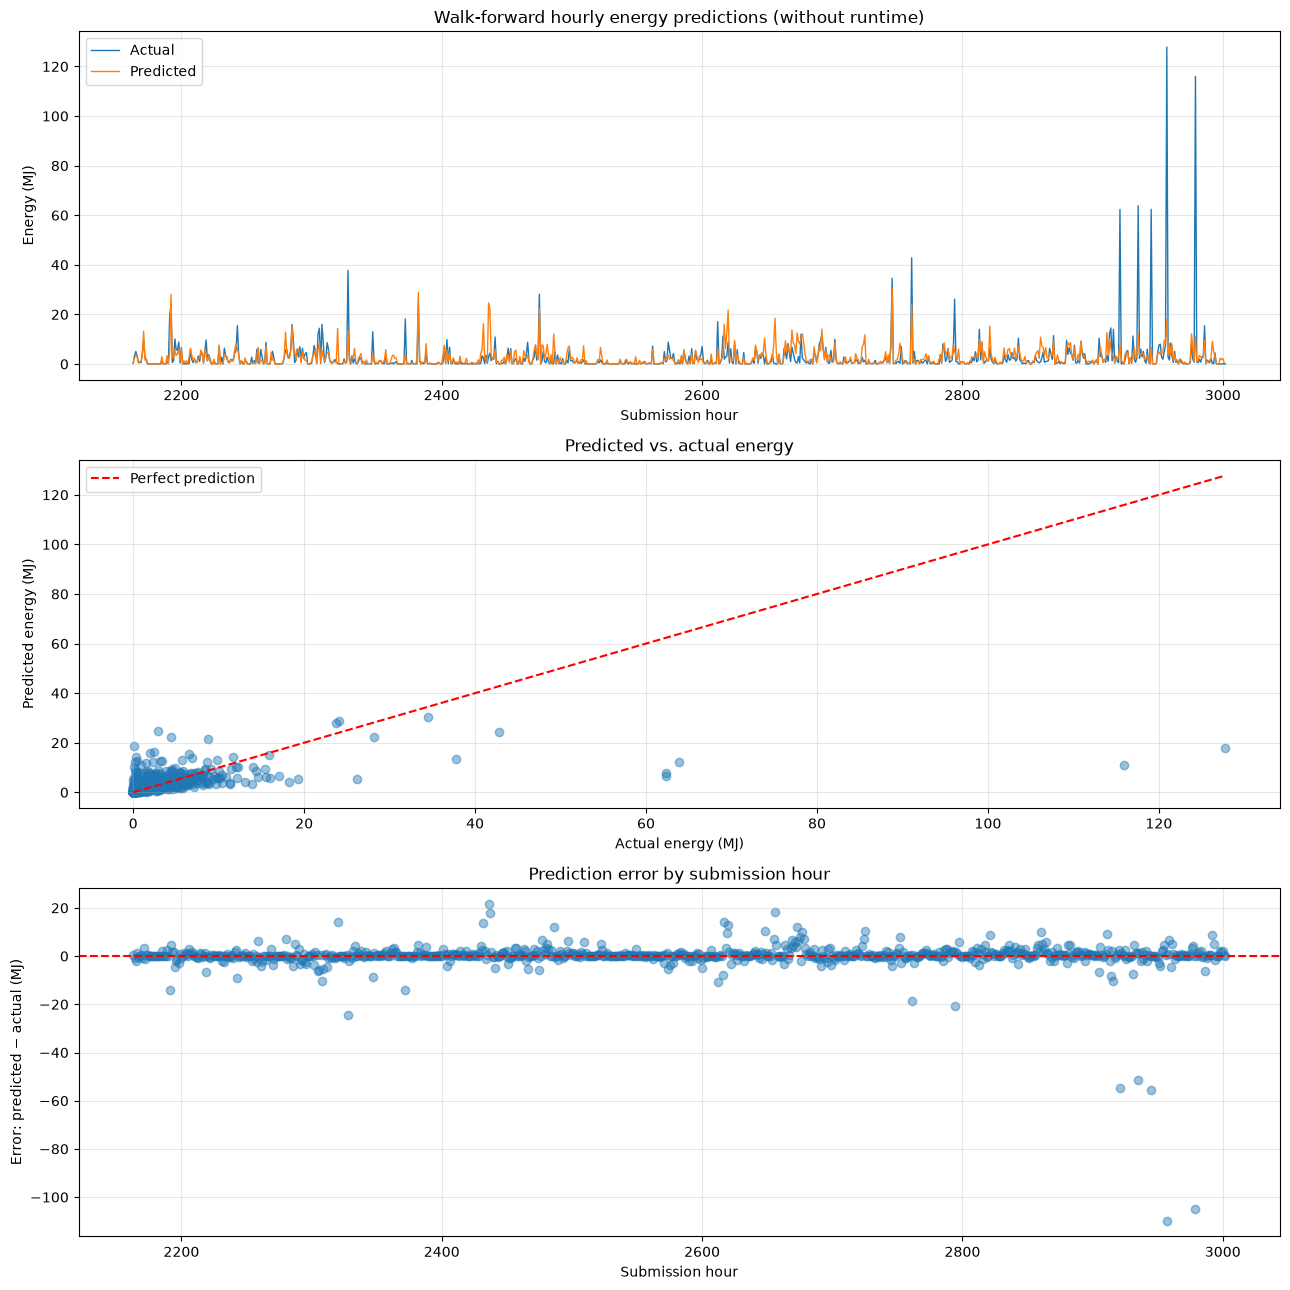

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

hourly = hourly.sort_values("submit_hour").reset_index(drop=True)

target = "hourly_energy_joules"
job_type_cols = [
    col for col in hourly.columns
    if col.startswith("jobs_type_")
]

# Runtime and timelimit are excluded
features = [
    "submit_hour",
    "n_jobs",
    "n_gpus",
    "n_cpus",
    "memory_bytes",
] + job_type_cols

splitter = TimeSeriesSplit(n_splits=5, test_size=168)
prediction_rows = []

for forecast_week, (train_idx, test_idx) in enumerate(splitter.split(hourly), start=1):
    model = make_rf()  
    model.fit(
        hourly.iloc[train_idx][features],
        hourly.iloc[train_idx][target],
    )

    test_rows = hourly.iloc[test_idx]
    predicted = model.predict(test_rows[features])

    prediction_rows.append(pd.DataFrame({
        "submit_hour": test_rows["submit_hour"].to_numpy(),
        "forecast_week": forecast_week,
        "actual_j": test_rows[target].to_numpy(),
        "predicted_j": predicted,
    }))

predictions = pd.concat(prediction_rows, ignore_index=True)
predictions["error_j"] = predictions["predicted_j"] - predictions["actual_j"]

print(
    f"Walk-forward without runtime — "
    f"MAE={mean_absolute_error(predictions['actual_j'], predictions['predicted_j']):,.1f} J | "
    f"RMSE={np.sqrt(mean_squared_error(predictions['actual_j'], predictions['predicted_j'])):,.1f} J | "
    f"R²={r2_score(predictions['actual_j'], predictions['predicted_j']):.3f}"
)

# Converting joules to megajoules for readable axes
actual_mj = predictions["actual_j"] / 1e6
predicted_mj = predictions["predicted_j"] / 1e6
error_mj = predictions["error_j"] / 1e6

fig, axes = plt.subplots(3, 1, figsize=(13, 13))

# Actual and predicted energy over the held-out hours
axes[0].plot(predictions["submit_hour"], actual_mj, label="Actual", linewidth=1)
axes[0].plot(predictions["submit_hour"], predicted_mj, label="Predicted", linewidth=1)
axes[0].set(
    title="Walk-forward hourly energy predictions (without runtime)",
    xlabel="Submission hour",
    ylabel="Energy (MJ)",
)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Predicted versus actual
axes[1].scatter(actual_mj, predicted_mj, alpha=0.45)
axis_max = max(actual_mj.max(), predicted_mj.max())
axes[1].plot([0, axis_max], [0, axis_max], "r--", label="Perfect prediction")
axes[1].set(
    title="Predicted vs. actual energy",
    xlabel="Actual energy (MJ)",
    ylabel="Predicted energy (MJ)",
)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Positive error means overprediction; negative means underprediction
axes[2].scatter(predictions["submit_hour"], error_mj, alpha=0.45)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set(
    title="Prediction error by submission hour",
    xlabel="Submission hour",
    ylabel="Error: predicted − actual (MJ)",
)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Plot of random forest without runtime

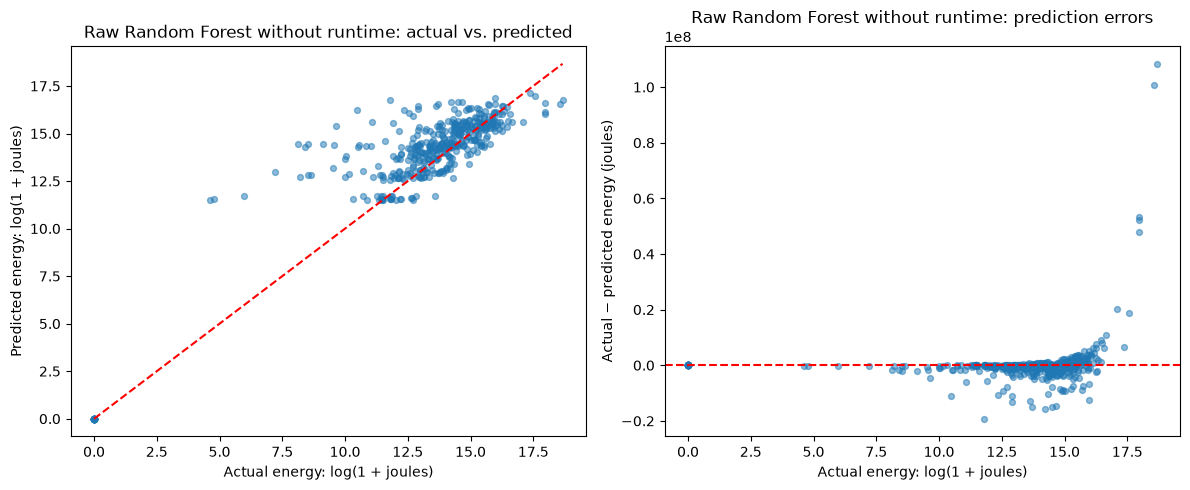

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

hourly = hourly.sort_values("submit_hour").reset_index(drop=True)

target = "hourly_energy_joules"
job_type_cols = [
    col for col in hourly.columns
    if col.startswith("jobs_type_")
]


feature_cols = [
    "submit_hour",
    "n_jobs",
    "n_gpus",
    "n_cpus",
    "memory_bytes",
] + job_type_cols

X = hourly[feature_cols].fillna(0)
y = hourly[target]

# 70/15/15 split
val_end = int(len(hourly) * 0.85)
X_train_val, y_train_val = X.iloc[:val_end], y.iloc[:val_end]
X_test_no_runtime, y_test_no_runtime = X.iloc[val_end:], y.iloc[val_end:]

rf_no_runtime = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=5,
    max_features=1.0,
    max_samples=0.7,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)
rf_no_runtime.fit(X_train_val, y_train_val)
rf_test_pred_no_runtime = rf_no_runtime.predict(X_test_no_runtime)

actual = np.asarray(y_test_no_runtime)
predicted = np.asarray(rf_test_pred_no_runtime)
residuals = actual - predicted

actual_log = np.log1p(actual)
predicted_log = np.log1p(predicted)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(actual_log, predicted_log, alpha=0.5, s=18)
low = min(actual_log.min(), predicted_log.min())
high = max(actual_log.max(), predicted_log.max())
axes[0].plot([low, high], [low, high], "r--")
axes[0].set(
    title="Raw Random Forest without runtime: actual vs. predicted",
    xlabel="Actual energy: log(1 + joules)",
    ylabel="Predicted energy: log(1 + joules)",
)

axes[1].scatter(actual_log, residuals, alpha=0.5, s=18)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set(
    title="Raw Random Forest without runtime: prediction errors",
    xlabel="Actual energy: log(1 + joules)",
    ylabel="Actual − predicted energy (joules)",
)

plt.tight_layout()
plt.show()